# 02 · Modelos de presión barométrica (Marco)
Sesión 4 · AireIQ · Equipo Novoa

**Pregunta predictiva:** ¿cuál será la presión dentro de **1 hora** y dentro de **3 horas**?

- **Entrada:** plata de Frank (`data/silver/mediciones_1min`).
- **Línea base:** persistencia (la presión dentro de H minutos será igual a la de ahora).
- **Candidatos:** regresión lineal, Ridge y Random Forest, con la hora del día como variable.
- **Salida:** modelos ganadores en `models/marco_presion/` y sus métricas en JSON.
- **Decisión:** avisar si el modelo prevé una caída fuerte de la presión en 3 horas.

In [1]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import SparkSession, functions as F

# Raíz del repositorio: sube hasta encontrar la carpeta data/
ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SILVER = ROOT / "data" / "silver" / "mediciones_1min"     # la plata que genera el cuaderno 01 de Frank
GOLD   = ROOT / "data" / "gold"
assert SILVER.exists(), "Falta la plata: corre primero frank_iaq/notebooks/01_bronce_plata_oro.ipynb"

spark = (SparkSession.builder.appName("aireiq-marco-02").master("local[2]")
         .config("spark.driver.memory", "1g")
         .config("spark.sql.session.timeZone", "America/Lima")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Raíz:", ROOT, "| Spark", spark.version)

MODELS = ROOT / "models" / "marco_presion"
MODELS.mkdir(parents=True, exist_ok=True)
s = spark.read.parquet(str(SILVER)).select("minuto", "presion_hpa")
print(f"Minutos en plata: {s.count():,}")

Raíz: /home/jovyan/work | Spark 3.5.3
Minutos en plata: 2,863


## 1 · Tabla de entrenamiento
Para cada minuto **t** armo estas variables:

| Variable | Qué es |
|---|---|
| `presion_hpa` | presión ahora |
| `presion_lag60` | presión hace 60 minutos |
| `presion_d60` | cuánto cambió en la última hora |
| `h24_sin`, `h24_cos` | la hora del día como un ciclo de 24 horas |
| `h12_sin`, `h12_cos` | la hora del día como un ciclo de **12 horas** (las dos subidas y bajadas de la marea) |

La hora se convierte en seno y coseno para que el modelo entienda que las 23:59 y las 00:00 están juntas. Los rezagos se buscan por **tiempo**: si falta ese minuto, la fila se descarta.

In [2]:
DOS_PI = 2 * math.pi

def desplazar(minutos, nombre):
    # presión en el minuto (t - minutos), pegada a la fila del minuto t
    return s.select((F.col("minuto") + F.expr(f"INTERVAL {minutos} MINUTES")).alias("minuto"),
                    F.col("presion_hpa").alias(nombre))

def objetivo(h):
    # presión en el minuto (t + h): lo que queremos predecir
    return s.select((F.col("minuto") - F.expr(f"INTERVAL {h} MINUTES")).alias("minuto"),
                    F.col("presion_hpa").alias(f"y_{h}"))

hora_dec = F.hour("minuto") + F.minute("minuto") / 60.0
base = (s.join(desplazar(60, "presion_lag60"), "minuto")
          .withColumn("presion_d60", F.col("presion_hpa") - F.col("presion_lag60"))
          .withColumn("h24_sin", F.sin(DOS_PI * hora_dec / 24)).withColumn("h24_cos", F.cos(DOS_PI * hora_dec / 24))
          .withColumn("h12_sin", F.sin(DOS_PI * hora_dec / 12)).withColumn("h12_cos", F.cos(DOS_PI * hora_dec / 12))
          .withColumn("ts", F.unix_timestamp("minuto")))

FEATS = ["presion_hpa", "presion_lag60", "presion_d60", "h24_sin", "h24_cos", "h12_sin", "h12_cos"]
base = base.cache()
print("Filas con rezago de 60 min:", base.count())

Filas con rezago de 60 min: 1992


## 2 · Corte cronológico
El 80 % más antiguo entrena y el 20 % más reciente prueba. Entre ambos dejo **3 horas de separación** (embargo), para que la presión que quiero predecir en las últimas filas de entrenamiento no caiga dentro del periodo de prueba. Así el modelo nunca ve el futuro.

In [3]:
corte = base.approxQuantile("ts", [0.8], 0.001)[0]
EMBARGO = 180 * 60
tr = base.filter(F.col("ts") <= corte - EMBARGO)
te = base.filter(F.col("ts") > corte)
fecha_corte = spark.range(1).select(F.from_unixtime(F.lit(int(corte)))).first()[0]
print("Corte:", fecha_corte, "| Entrenamiento:", tr.count(), "| Prueba:", te.count())

Corte: 2026-11-01 15:24:00 | Entrenamiento: 1552 | Prueba: 400


## 3 · Modelos a 1 hora y a 3 horas
Para cada horizonte comparo la persistencia con tres modelos. Mido el error con **RMSE** y **MAE** (en hPa, menor es mejor) y la **mejora** frente a la persistencia.

In [4]:
HORIZONTES = (60, 180)

def candidatos(h):
    y = f"y_{h}"
    return {
        "Lineal":       LinearRegression(featuresCol="x", labelCol=y),
        "Ridge":        LinearRegression(featuresCol="x", labelCol=y, regParam=0.1, elasticNetParam=0.0),
        "RandomForest": RandomForestRegressor(featuresCol="x", labelCol=y, numTrees=60, maxDepth=6, seed=42),
    }

def pipeline(modelo):
    return Pipeline(stages=[VectorAssembler(inputCols=FEATS, outputCol="x_raw", handleInvalid="skip"),
                            StandardScaler(inputCol="x_raw", outputCol="x", withMean=True, withStd=True),
                            modelo])

def metricas(pred, y):
    ev = lambda m: RegressionEvaluator(labelCol=y, predictionCol="prediction", metricName=m).evaluate(pred)
    return ev("rmse"), ev("mae")

filas, guardados = [], {}
for h in HORIZONTES:
    y = f"y_{h}"
    tr_h, te_h = tr.join(objetivo(h), "minuto"), te.join(objetivo(h), "minuto")
    rm, ma = metricas(te_h.withColumn("prediction", F.col("presion_hpa")), y)
    filas.append(dict(horizonte_min=h, modelo="Persistencia", rmse=rm, mae=ma, n_prueba=te_h.count()))
    for nombre, est in candidatos(h).items():
        m = pipeline(est).fit(tr_h)
        rm, ma = metricas(m.transform(te_h), y)
        filas.append(dict(horizonte_min=h, modelo=nombre, rmse=rm, mae=ma, n_prueba=te_h.count()))
        guardados[(h, nombre)] = m

res = pd.DataFrame(filas)
pers = res[res.modelo == "Persistencia"].set_index("horizonte_min")["rmse"]
res["mejora_vs_persistencia_%"] = res.apply(lambda r: round(100 * (pers[r.horizonte_min] - r.rmse) / pers[r.horizonte_min], 1), axis=1)
res[["rmse", "mae"]] = res[["rmse", "mae"]].round(3)
res

,horizonte_min,modelo,rmse,mae,n_prueba,mejora_vs_persistencia_%
0,60,Persistencia,0.241,0.193,262,0.0
1,60,Lineal,0.228,0.196,262,5.5
2,60,Ridge,0.188,0.155,262,22.1
3,60,RandomForest,0.221,0.159,262,8.2
4,180,Persistencia,1.265,0.903,229,0.0
5,180,Lineal,0.558,0.411,229,55.9
6,180,Ridge,0.544,0.443,229,57.0
7,180,RandomForest,0.722,0.409,229,42.9


**Cómo leer la tabla:** cada fila es un método en un horizonte. Una mejora positiva significa que el modelo se equivoca menos que repetir la presión actual. Lo esperable: a 1 hora la ventaja es pequeña, porque en una hora la presión cambia poco; a 3 horas la hora del día pesa más y la ventaja crece.

## 4 · Ganador por horizonte y guardado
Elijo el de menor RMSE en la prueba y lo guardo como `PipelineModel`, el formato que Spark Streaming carga sin reentrenar.

In [5]:
ganadores = {}
for h in HORIZONTES:
    sub = res[(res.horizonte_min == h) & (res.modelo != "Persistencia")].sort_values("rmse")
    mejor = sub.iloc[0]
    ruta = MODELS / f"presion_h{h}"
    guardados[(h, mejor.modelo)].write().overwrite().save(str(ruta))
    ganadores[h] = dict(modelo=mejor.modelo, rmse=float(mejor.rmse), mae=float(mejor.mae),
                        rmse_persistencia=float(pers[h]), mejora_pct=float(mejor["mejora_vs_persistencia_%"]),
                        supera_persistencia=bool(mejor.rmse < pers[h]))
    print(f"h={h:>3} min -> {mejor.modelo:<12} RMSE {mejor.rmse:.3f} vs persistencia {pers[h]:.3f} "
          f"({mejor['mejora_vs_persistencia_%']:+.1f} %)  guardado en {ruta.name}")

_ = (MODELS / "metricas_regresion.json").write_text(json.dumps(
    dict(corte=str(fecha_corte), embargo_s=EMBARGO, predictores=FEATS, ganadores=ganadores,
         tabla=res.to_dict(orient="records")), indent=2, ensure_ascii=False))

h= 60 min -> Ridge        RMSE 0.188 vs persistencia 0.241 (+22.1 %)  guardado en presion_h60
h=180 min -> Ridge        RMSE 0.544 vs persistencia 1.265 (+57.0 %)  guardado en presion_h180


## 5 · Probar el modelo guardado (inferencia sin reentrenar)
Cargo el modelo desde el disco, como lo hará el streaming, y lo aplico a la prueba.

RMSE del modelo cargado: 0.544 hPa


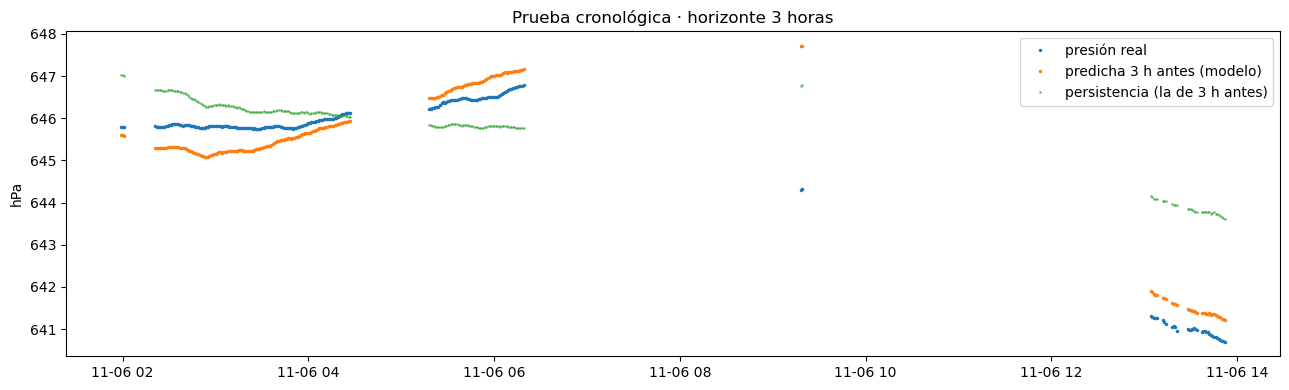

In [6]:
H = 180
m = PipelineModel.load(str(MODELS / f"presion_h{H}"))
te_h = te.join(objetivo(H), "minuto")
pred = m.transform(te_h)
print("RMSE del modelo cargado:", round(RegressionEvaluator(labelCol=f"y_{H}", predictionCol="prediction", metricName="rmse").evaluate(pred), 3), "hPa")

pdf = pred.select("minuto", "presion_hpa", f"y_{H}", "prediction").orderBy("minuto").toPandas()
pdf["minuto_objetivo"] = pdf["minuto"] + pd.Timedelta(minutes=H)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pdf["minuto_objetivo"], pdf[f"y_{H}"], ".", ms=3, label="presión real")
ax.plot(pdf["minuto_objetivo"], pdf["prediction"], ".", ms=3, label="predicha 3 h antes (modelo)")
ax.plot(pdf["minuto_objetivo"], pdf["presion_hpa"], ".", ms=2, alpha=0.5, label="persistencia (la de 3 h antes)")
ax.set_ylabel("hPa"); ax.legend(); ax.set_title("Prueba cronológica · horizonte 3 horas")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico:** el eje horizontal es el momento que se quería predecir. Si los puntos del modelo están encima de los de la presión real, acertó. La persistencia va "atrasada": repite la presión de 3 horas antes, así que se separa cuando la marea sube o baja.

## 6 · Decisión: alerta de caída fuerte en 3 horas
**Caída fuerte real:** la presión baja en 3 horas tanto como el 5 % de las caídas más fuertes del entrenamiento.

**Problema:** toda regresión suaviza los extremos. Mi modelo acierta la tendencia, pero casi nunca predice una caída tan grande como las reales. Si exijo que prevea la misma caída, la alerta no suena nunca (lo muestra la primera línea de la salida).

**Solución:** calibro el **límite del aviso** con el entrenamiento. Pruebo varios valores de *caída prevista* y elijo el que mejor detecta las caídas fuertes reales en el entrenamiento (mayor F1). La prueba no se usa para elegirlo.

Una caída fuerte puede anunciar un cambio de tiempo, pero no tenemos datos de lluvia para comprobarlo: es una **señal de alerta**, no una predicción de lluvia.

In [7]:
import numpy as np

tr_h = tr.join(objetivo(H), "minuto")
umbral = (tr_h.withColumn("cambio_real", F.col(f"y_{H}") - F.col("presion_hpa"))
              .approxQuantile("cambio_real", [0.05], 0.001)[0])
print(f"Caída fuerte real (p5 del cambio en 3 h, entrenamiento): {umbral:.2f} hPa")

def cambios(df):
    return (df.withColumn("cambio_real", F.col(f"y_{H}") - F.col("presion_hpa"))
              .withColumn("cambio_pred", F.col("prediction") - F.col("presion_hpa"))
              .select("cambio_real", "cambio_pred").toPandas())

ent, pru = cambios(m.transform(tr_h)), cambios(pred)
print(f"Caída prevista más fuerte · entrenamiento: {ent.cambio_pred.min():.2f} hPa | prueba: {pru.cambio_pred.min():.2f} hPa")

def evaluar(t, limite):
    real, aviso = t.cambio_real <= umbral, t.cambio_pred <= limite
    tp, fp = int((real & aviso).sum()), int((~real & aviso).sum())
    fn, tn = int((real & ~aviso).sum()), int((~real & ~aviso).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=round(p, 2), recall=round(r, 2), f1=round(f1, 2))

print("Sin calibrar (avisar solo si prevé la misma caída):", evaluar(pru, umbral))

opciones = [round(float(x), 2) for x in np.arange(-3.0, -0.95, 0.05)]
limite = max(opciones, key=lambda c: evaluar(ent, c)["f1"])
print(f"Límite de aviso calibrado en entrenamiento: caída prevista <= {limite:.2f} hPa")

res_alerta = pd.DataFrame([dict(periodo="entrenamiento", **evaluar(ent, limite)),
                           dict(periodo="prueba", **evaluar(pru, limite))])
_ = (MODELS / "alerta_caida_3h.json").write_text(json.dumps(
    dict(horizonte_min=H, caida_fuerte_real_hpa=float(umbral), limite_aviso_hpa=limite,
         tabla=res_alerta.to_dict(orient="records")), indent=2))
res_alerta

Caída fuerte real (p5 del cambio en 3 h, entrenamiento): -2.51 hPa
Caída prevista más fuerte · entrenamiento: -2.70 hPa | prueba: -2.41 hPa
Sin calibrar (avisar solo si prevé la misma caída): {'TP': 0, 'FP': 0, 'FN': 35, 'TN': 194, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
Límite de aviso calibrado en entrenamiento: caída prevista <= -1.95 hPa


,periodo,TP,FP,FN,TN,precision,recall,f1
0,entrenamiento,28,69,0,472,0.29,1.0,0.45
1,prueba,35,0,0,194,1.00,1.0,1.00


**Cómo leer la tabla:** TP son caídas fuertes avisadas a tiempo; FP, avisos que no hacían falta; FN, caídas fuertes que se escaparon; TN, momentos tranquilos sin aviso. El recall dice qué parte de las caídas fuertes se detectó; la precisión, qué parte de los avisos fue útil. Ojo: si las caídas fuertes de la prueba vienen de un solo episodio, un resultado perfecto ahí no garantiza lo mismo con datos nuevos.

## 7 · Una lectura nueva: ¿qué predice el modelo?
Un caso inventado, como si llegara del sensor a las 13:00: presión 644,0 hPa y una hora antes 644,8 hPa.

In [8]:
hora = 13.0
una = spark.createDataFrame([dict(presion_hpa=644.0, presion_lag60=644.8, presion_d60=-0.8,
                                  h24_sin=math.sin(DOS_PI * hora / 24), h24_cos=math.cos(DOS_PI * hora / 24),
                                  h12_sin=math.sin(DOS_PI * hora / 12), h12_cos=math.cos(DOS_PI * hora / 12))])
p = m.transform(una).first()["prediction"]
print(f"Presión ahora 644.00 hPa -> predicha a las 16:00: {p:.2f} hPa | cambio previsto {p - 644.0:+.2f} hPa | ¿alerta? {p - 644.0 <= limite}")

Presión ahora 644.00 hPa -> predicha a las 16:00: 642.70 hPa | cambio previsto -1.30 hPa | ¿alerta? False


## 8 · Conclusiones (escríbelas con tus palabras después de ejecutar)
- **Resultado a 1 hora:** …
- **Resultado a 3 horas:** …
- **Por qué funciona (o no):** …
- **Límites:** pocos días de datos con huecos; un solo sensor; sin datos de lluvia para validar la alerta.
- **Siguiente paso:** usar `models/marco_presion/presion_h180` en el consumidor de streaming y mostrar real contra predicha en Grafana.